# Bayesian Monetary Policy and Recession Risk

An applied econometrics investigation with reusable Python models, explicit timing contracts, and independent numerical controls. This notebook inspects the generated empirical artifacts; it does not contain a second estimation implementation.

**Questions:** Does an asymmetric output-gap response justify another policy coefficient? What do financial signals imply about recession probabilities twelve months ahead? [Full methods](../docs/methods.md) · [Reference audit](../docs/reference_audit.md) · [Empirical report](../results/report.md)

In [1]:
from pathlib import Path
import json
import os
import pandas as pd
from IPython.display import Image, display
ROOT = Path.cwd()
if not (ROOT / 'results').is_dir():
    ROOT = ROOT / 'project2' if (ROOT / 'project2/results').is_dir() else ROOT.parent
assert (ROOT / 'results/policy_posterior.csv').is_file(), 'Run the policy pipeline first'
RESULTS = ROOT / 'results'
pd.options.display.float_format = '{:.5f}'.format

## Optional reproduction from the private inputs

The default notebook run reads committed results and requires no workbooks. To regenerate estimates, set `RUN_ESTIMATION=1`, `POLICY_DATA`, and `RECESSION_DATA` to the external workbook paths before starting the kernel. The commands in the README provide the equivalent CLI. No originals are copied into the repository.

In [2]:
if os.environ.get('RUN_ESTIMATION') == '1':
    from bayes_policy.pipeline import run_policy, run_recession
    from bayes_policy.reporting import build_report
    from bayes_policy.samplers import SamplerConfig
    config = SamplerConfig(draws=10000, warmup=3000, chains=4, seed=20261114)
    policy_validation = run_policy(os.environ['POLICY_DATA'], RESULTS, config)
    recession_validation = run_recession(os.environ['RECESSION_DATA'], RESULTS / 'recession', config)
    delayed_validation = run_recession(os.environ['RECESSION_DATA'], RESULTS / 'recession_delay18',
                                       config, label_delay_months=18)
    assert policy_validation['sampler_diagnostics_passed']
    assert policy_validation['independent_evidence_controls_passed']
    assert recession_validation['all_diagnostics_passed']
    assert delayed_validation['all_diagnostics_passed']
    build_report(RESULTS)
else:
    print('Inspecting generated empirical artifacts; no estimation rerun requested.')

Inspecting generated empirical artifacts; no estimation rerun requested.


## Audit the actual sample

The quarterly workbook begins in 1954Q4. One lag leaves 239 effective responses, 1955Q1–2014Q3. Trend inflation and data vintage are accepted as supplied, not independently reconstructed. The missing earlier quarters are not invented.

In [3]:
manifest = json.loads((RESULTS / 'data_manifest.json').read_text())
display(pd.Series(manifest, name='Policy input provenance').to_frame())

,Policy input provenance
input,int_rate_rule_data.xlsx
sha256,39e168ac38890809c3c701c7ffa8e0b66aa8b3fcb98efb...
raw_rows,240
raw_start,1954-10-01
raw_end,2014-07-01
effective_n,239
effective_start,1955-01-01
effective_end,2014-07-01
frequency,quarterly
inflation_gap,"PI - PI_Target, percentage points as supplied"


## Policy responses and prior sensitivity

Both policy specifications use independent Normal/Gamma priors. The primary coefficient covariance is 10I; the 5I sensitivity follows the supplied MATLAB program. Negative output gaps keep their sign. Intervals below are central 90% posterior intervals.

,parameter,mean,median,sd,p05,p95,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat,ols,model
0,intercept,0.36383,0.36454,0.10193,0.19602,0.53028,0.00051,0.00037,39791.90718,39185.09167,1.00005,0.36417,symmetric_v10
1,inflation_gap,0.11754,0.11746,0.03523,0.05986,0.17536,0.00018,0.00013,39898.02290,38656.47228,0.99999,0.11743,symmetric_v10
2,output_gap,0.10730,0.10735,0.02064,0.07368,0.14119,0.00010,0.00007,39805.97497,39885.63455,0.99992,0.10736,symmetric_v10
3,lagged_rate,0.92651,0.92655,0.01865,0.89582,0.95702,0.00009,0.00007,40119.18332,39240.67562,1.00002,0.92648,symmetric_v10
4,sigma2,0.69673,0.69209,0.06472,0.59843,0.80969,0.00033,0.00025,38756.42250,38614.41518,0.99997,NaN,symmetric_v10
5,intercept,0.44395,0.44315,0.12938,0.23155,0.65664,0.00064,0.00046,40263.06012,39557.09371,0.99999,0.44376,asymmetric_v10
6,inflation_gap,0.12142,0.12172,0.03550,0.06291,0.17958,0.00018,0.00013,40234.68867,38964.45853,1.00002,0.12131,asymmetric_v10
7,output_gap_positive,0.06197,0.06160,0.05028,-0.02082,0.14464,0.00025,0.00018,39570.37345,40097.93352,1.00002,0.06167,asymmetric_v10
8,output_gap_negative,0.13252,0.13271,0.03252,0.07940,0.18604,0.00016,0.00012,40166.14959,39594.05355,0.99997,0.13252,asymmetric_v10
9,lagged_rate,0.92346,0.92346,0.01884,0.89259,0.95431,0.00009,0.00007,40622.82914,39831.08585,1.00005,0.92358,asymmetric_v10


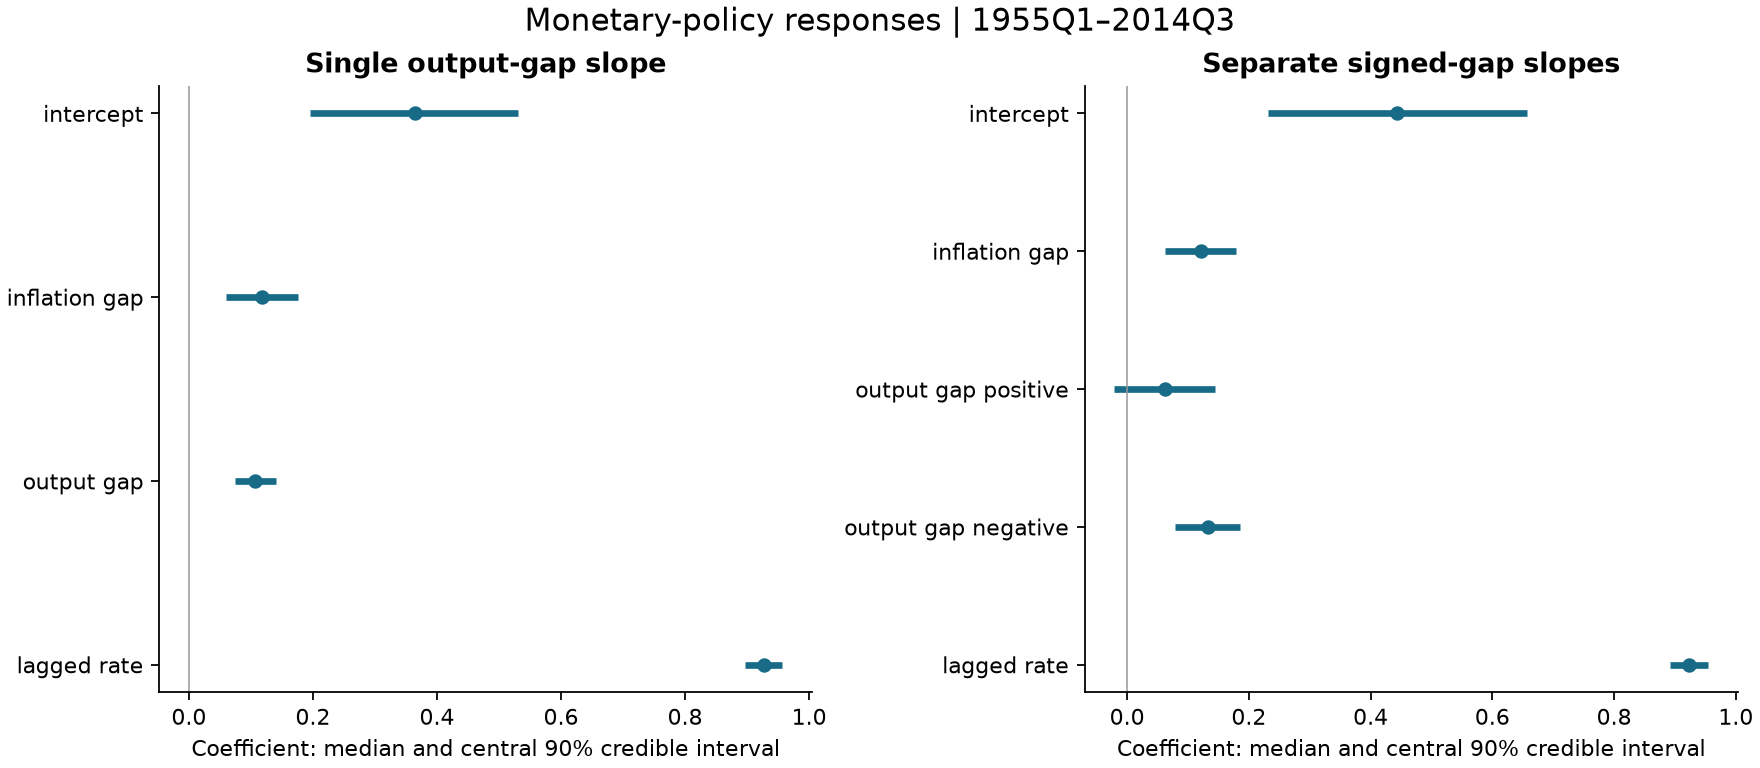

In [4]:
posterior = pd.read_csv(RESULTS / 'policy_posterior.csv')
display(posterior[posterior['model'].isin(['symmetric_v10', 'asymmetric_v10'])])
display(Image(filename=str(RESULTS / 'figures/policy_coefficients.png')))

## Model complexity must earn its place

Chib evidence and the independent quadrature control agree closely. The comparison uses identical response observations and explicit prior model probabilities. A posterior model weight measures preference within these candidates; it is not a probability that the chosen economic model is universally correct.

In [5]:
evidence = pd.read_csv(RESULTS / 'model_comparison.csv')
display(evidence)
assert evidence['evidence_control_passed'].all()

,model,prior_variance,log_evidence_chib,mcse_log_evidence_chib,log_evidence_quadrature,quadrature_relative_error,chib_minus_quadrature,agreement_tolerance,evidence_control_passed,posterior_model_probability,probability_if_prior_asymmetric_0_25,probability_if_prior_asymmetric_0_75
0,symmetric_v10,10.00000,-313.62736,0.00009,-313.62742,0.00000,0.00006,0.01000,True,0.96444,0.98786,0.90039
1,asymmetric_v10,10.00000,-316.92758,0.00011,-316.92766,0.00000,0.00007,0.01000,True,0.03556,0.01214,0.09961
2,symmetric_v5,5.00000,-312.29248,0.00009,-312.29254,0.00000,0.00006,0.01000,True,0.95062,0.98298,0.86518
3,asymmetric_v5,5.00000,-315.25007,0.00011,-315.25014,0.00000,0.00007,0.01000,True,0.04938,0.01702,0.13482


## Long-run response and asymmetry

The positive-response and Taylor-principle thresholds are distinct: theta>0 versus theta>1, where theta is the inflation coefficient divided by one minus the lag coefficient. Unstable and near-unit-root draws remain visible. The joint slope difference measures asymmetry more directly than comparing two marginal intervals.

,unstable_draw_fraction,near_unit_root_fraction_abs_one_minus_rho_below_0_01,theta_median,theta_p05,theta_p95,theta_gt1_given_stable,long_run_positive.probability,long_run_positive.mcse,long_run_positive.no_observed_transitions,long_run_above_one.probability,long_run_above_one.mcse,long_run_above_one.no_observed_transitions,positive_minus_negative_gap_above_zero.probability,positive_minus_negative_gap_above_zero.mcse,positive_minus_negative_gap_above_zero.no_observed_transitions
model,,,,,,,,,,,,,,,
symmetric_v10,0.00013,0.00032,1.59902,0.94674,2.48152,0.93442,0.99943,0.00012,False,0.93430,0.00125,False,NaN,NaN,NaN
asymmetric_v10,0.00003,0.00015,1.58492,0.96137,2.40288,0.93815,0.99965,0.00009,False,0.93812,0.00121,False,0.15830,0.00182,False
symmetric_v5,0.00013,0.00032,1.59946,0.94702,2.48232,0.93449,0.99943,0.00012,False,0.93437,0.00125,False,NaN,NaN,NaN
asymmetric_v5,0.00003,0.00015,1.58558,0.96167,2.40419,0.93827,0.99965,0.00009,False,0.93825,0.00121,False,0.15895,0.00183,False


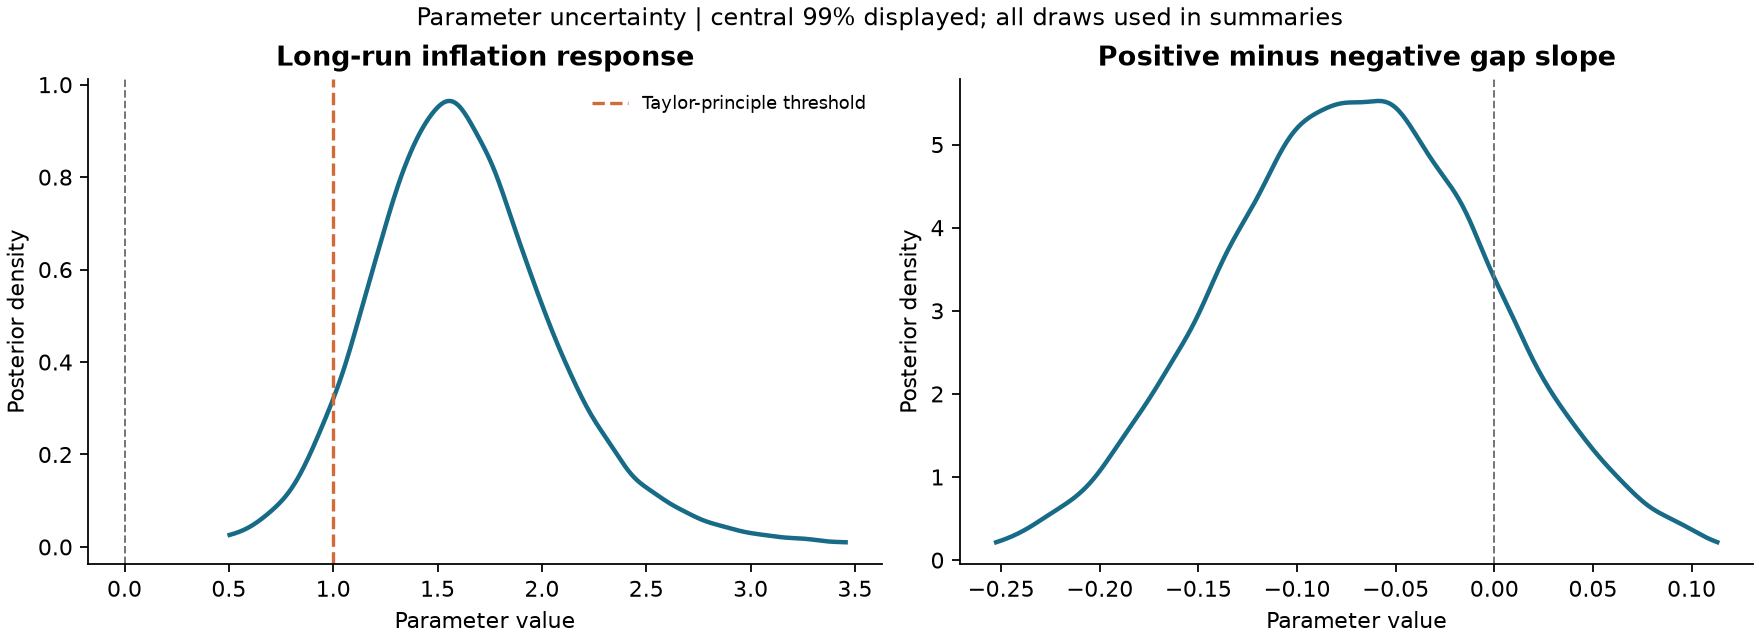

In [6]:
derived = json.loads((RESULTS / 'policy_derived.json').read_text())
display(pd.json_normalize(derived).set_index('model'))
display(Image(filename=str(RESULTS / 'figures/policy_uncertainty.png')))

## A reliable sampler can fit an inadequate likelihood

Four-chain rank-normalized split R-hat, bulk/tail ESS, and MCSE assess simulation reliability. The conditional residual check examines economic-model adequacy. Residual serial dependence challenges the independent Gaussian error assumption; regime changes and the lower bound also limit interpretation. These regressions do not identify causal policy effects.

,0
symmetric_v10.sampler.passed,True
symmetric_v10.sampler.max_rhat,1.00005
symmetric_v10.sampler.min_bulk_ess,38756.42250
symmetric_v10.sampler.min_tail_ess,38614.41518
symmetric_v10.sampler.thresholds.rhat_max,1.01000
...,...
asymmetric_v5.predictive_check.type,fixed-design conditional posterior predictive ...
asymmetric_v5.predictive_check.residual_lag1_acf_at_posterior_mean,0.17658
asymmetric_v5.predictive_check.ppp_abs_lag1_acf,0.00500
asymmetric_v5.predictive_check.draws_used,2000


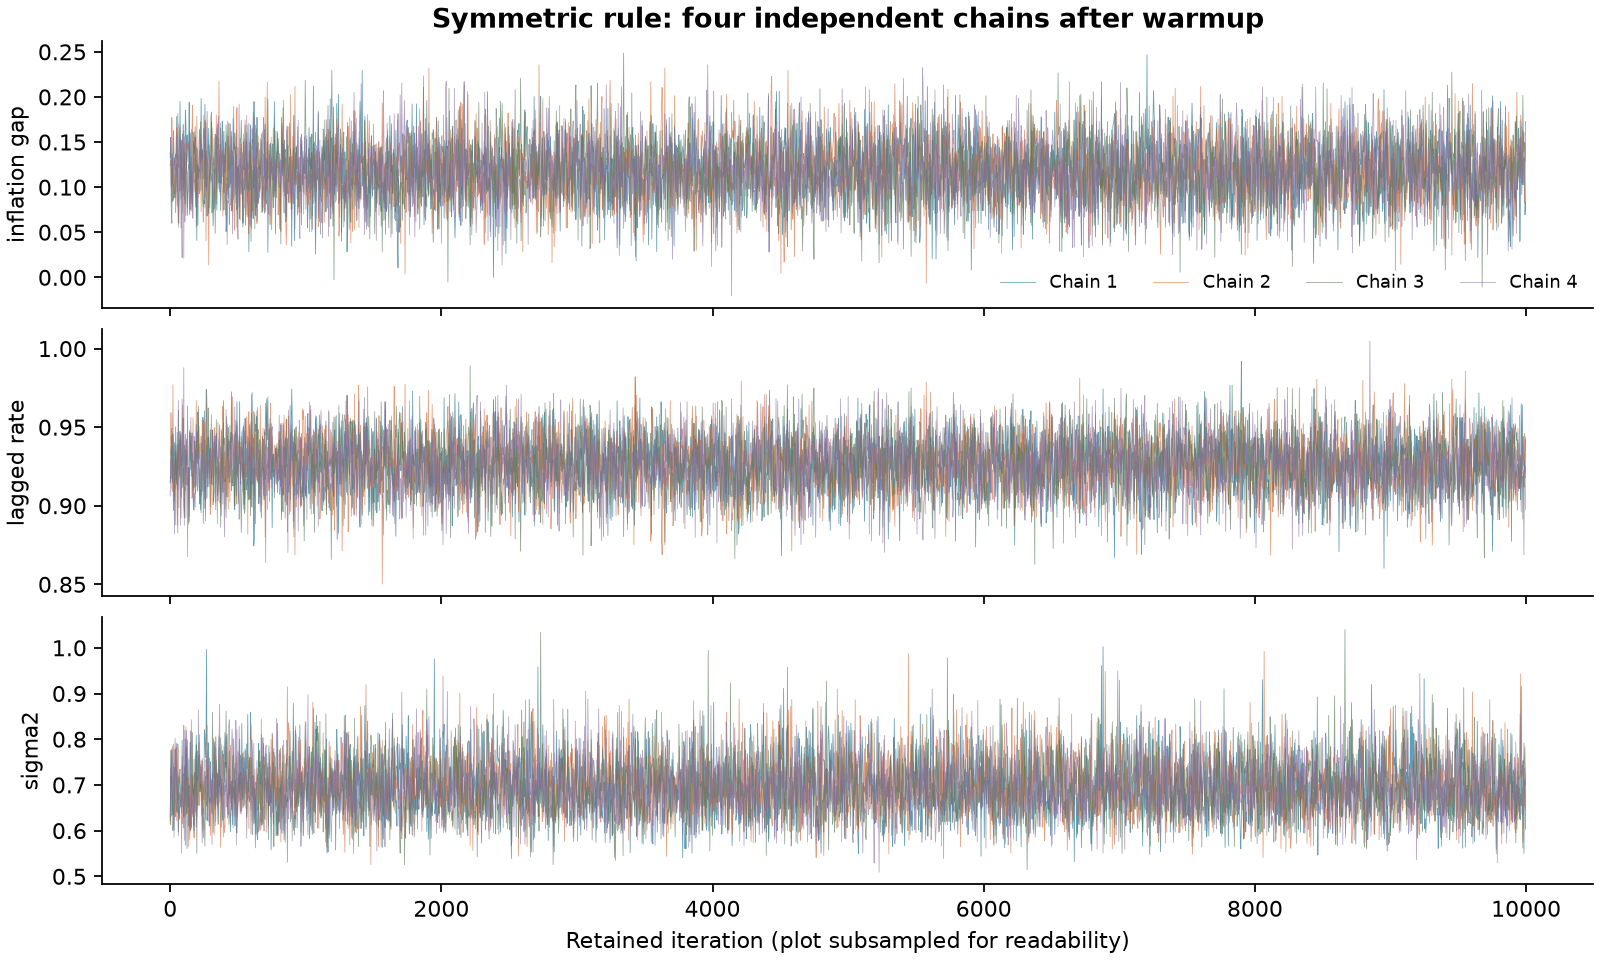

In [7]:
validation = json.loads((RESULTS / 'validation.json').read_text())
display(pd.json_normalize(validation['models'], sep='.').T)
assert validation['sampler_diagnostics_passed']
display(Image(filename=str(RESULTS / 'figures/policy_traces.png')))

## Recession forecasts: origin, target, availability

A 2007 forecast uses that origin's predictors and trains only on already matured targets, with the declared availability rule. The primary run assumes zero additional label delay and retrospective recession indicators. Predictor vintages and actual announcement times are unverified, so the exercise is **pseudo-real-time**. The February 2026-origin forecast targets February 2027 and has no outcome in the input; it is a historical-origin forecast.

,Monthly input provenance
input,Recession_Forecast_Data.xlsx
sha256,0d6605fa63413acbb64f690dbcd55a3ec35616df7ef85b...
raw_rows,794
start,1960-01-31
end,2026-02-28
equity_return,"100*(SP500_t/SP500_(t-3)-1), simple percent re..."
spread,"TenYearBondYield - ThreeMonthBillYield, percen..."
horizon,12
prior_covariance,"10 I, independent normal coefficients"
latent_variance,1


,origin,last_training_predictor,last_training_target,latest_label_availability,training_n,horizon_months,label_policy,evaluation_type,target_date,actual,probability,probability_p05,probability_p95,probability_mcse,benchmark_probability,diagnostics_passed,max_rhat,min_bulk_ess,min_tail_ess
0,2007-01-31,2006-01-31,2007-01-31,2007-01-31,550,12,assumed 0-month label delay; retrospective labels,pseudo-real-time,2008-01-31,1.00000,0.20025,0.13196,0.27709,0.00059,0.11957,True,1.00339,2232.01908,4784.84066
1,2007-02-28,2006-02-28,2007-02-28,2007-02-28,551,12,assumed 0-month label delay; retrospective labels,pseudo-real-time,2008-02-29,1.00000,0.21536,0.14163,0.29861,0.00064,0.11935,True,1.00204,2528.35244,4922.94469
2,2007-03-31,2006-03-31,2007-03-31,2007-03-31,552,12,assumed 0-month label delay; retrospective labels,pseudo-real-time,2008-03-31,1.00000,0.23416,0.15742,0.31919,0.00063,0.11913,True,1.00067,2528.49529,4665.81997
3,2007-04-30,2006-04-30,2007-04-30,2007-04-30,553,12,assumed 0-month label delay; retrospective labels,pseudo-real-time,2008-04-30,1.00000,0.19373,0.13076,0.26544,0.00052,0.11892,True,1.00198,2298.03991,4824.76952
4,2007-05-31,2006-05-31,2007-05-31,2007-05-31,554,12,assumed 0-month label delay; retrospective labels,pseudo-real-time,2008-05-31,1.00000,0.15902,0.10558,0.22068,0.00045,0.11871,True,1.00117,2160.45272,4721.69068
5,2007-06-30,2006-06-30,2007-06-30,2007-06-30,555,12,assumed 0-month label delay; retrospective labels,pseudo-real-time,2008-06-30,1.00000,0.09742,0.06099,0.14034,0.00035,0.11849,True,1.00227,2393.27366,4712.61810
6,2007-07-31,2006-07-31,2007-07-31,2007-07-31,556,12,assumed 0-month label delay; retrospective labels,pseudo-real-time,2008-07-31,1.00000,0.13640,0.09164,0.18719,0.00039,0.11828,True,1.00286,2260.08151,4625.08708
7,2007-08-31,2006-08-31,2007-08-31,2007-08-31,557,12,assumed 0-month label delay; retrospective labels,pseudo-real-time,2008-08-31,1.00000,0.10414,0.06686,0.14715,0.00035,0.11807,True,1.00117,2291.86350,4673.82962
8,2007-09-30,2006-09-30,2007-09-30,2007-09-30,558,12,assumed 0-month label delay; retrospective labels,pseudo-real-time,2008-09-30,1.00000,0.08301,0.05419,0.11631,0.00030,0.11786,True,1.00079,2574.99279,4952.39754
9,2007-10-31,2006-10-31,2007-10-31,2007-10-31,559,12,assumed 0-month label delay; retrospective labels,pseudo-real-time,2008-10-31,1.00000,0.07711,0.05028,0.10821,0.00029,0.11765,True,1.00151,2340.33924,4631.76034


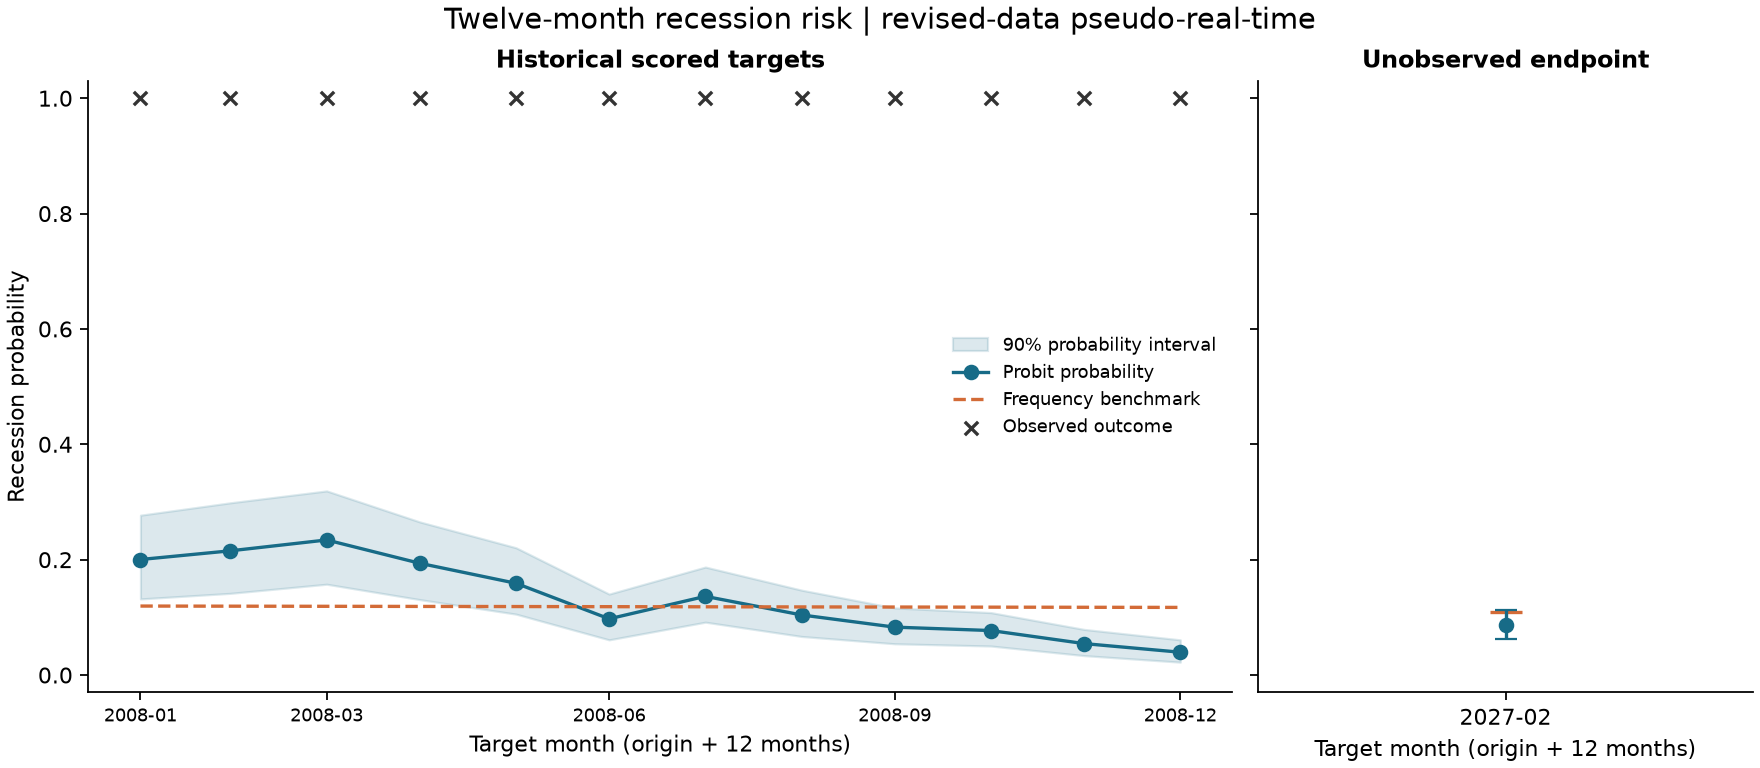

In [8]:
recession_manifest = json.loads((RESULTS / 'recession/recession_manifest.json').read_text())
display(pd.Series({k: v for k, v in recession_manifest.items() if k != 'metadata'},
                  name='Monthly input provenance').to_frame())
forecasts = pd.read_csv(RESULTS / 'recession/recession_forecasts.csv')
display(forecasts)
assert (pd.to_datetime(forecasts.last_training_target) <= pd.to_datetime(forecasts.origin)).all()
assert (pd.to_datetime(forecasts.latest_label_availability) <= pd.to_datetime(forecasts.origin)).all()
assert forecasts.diagnostics_passed.all()
display(Image(filename=str(RESULTS / 'recession/recession_probabilities.png')))

## Financial signals in the endpoint model

The February 2026-origin coefficient posterior summarizes 779 matched observations. Coefficients describe changes in the latent probit index, not direct percentage-point probability changes or causal effects. Conditional predictor relationships need to be interpreted jointly with the model and its timing assumptions.

,parameter,mean,median,sd,p05,p95,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
0,intercept,-1.52657,-1.52565,0.17175,-1.81063,-1.24672,0.00226,0.00115,5770.36816,11225.74088,1.00057
1,federal_funds_rate,0.11582,0.11579,0.02053,0.08223,0.14991,0.00027,0.00014,5968.75789,11129.15341,1.00056
2,equity_return_3m,-0.01938,-0.01936,0.01044,-0.03654,-0.00216,0.00014,0.00007,5337.35979,11234.44314,1.00048
3,term_spread,-0.41538,-0.41469,0.06637,-0.52570,-0.30740,0.00114,0.00049,3374.39846,8712.27164,1.00146


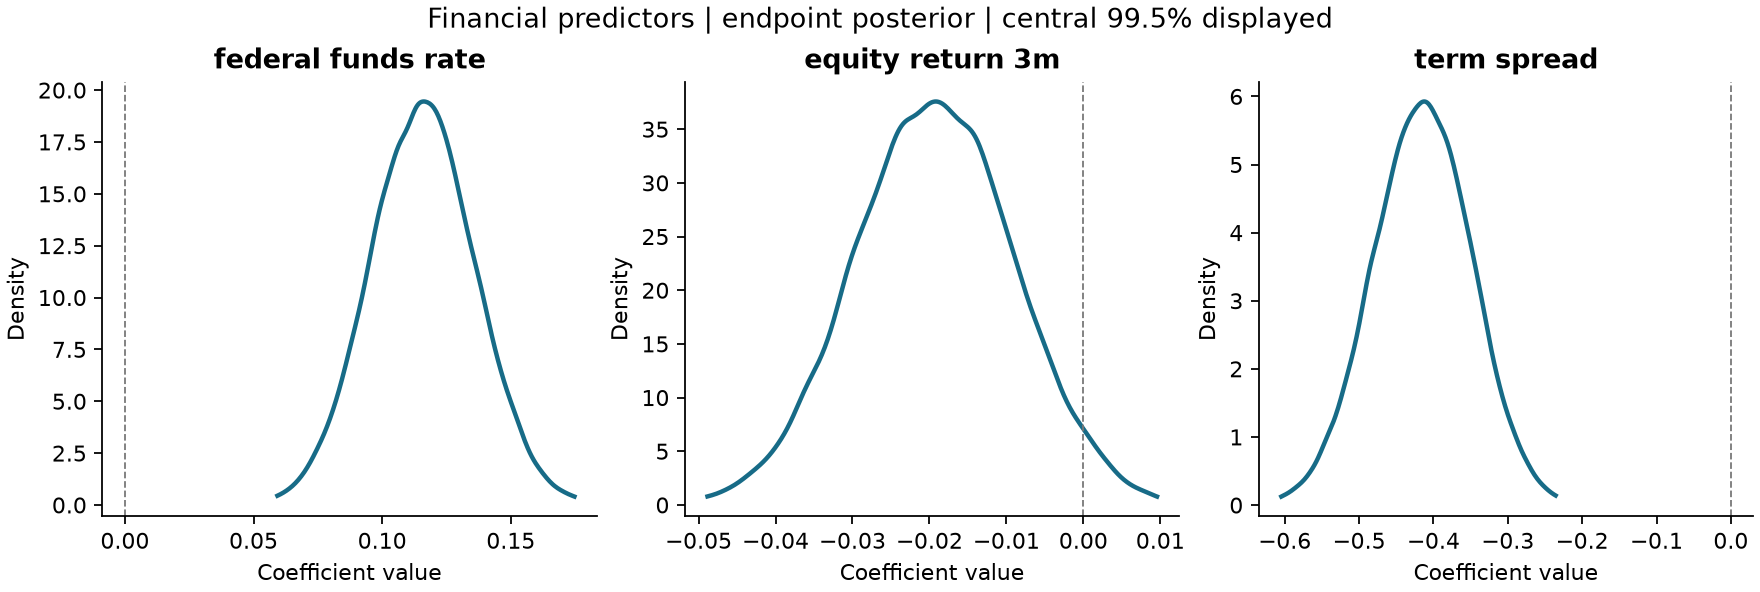

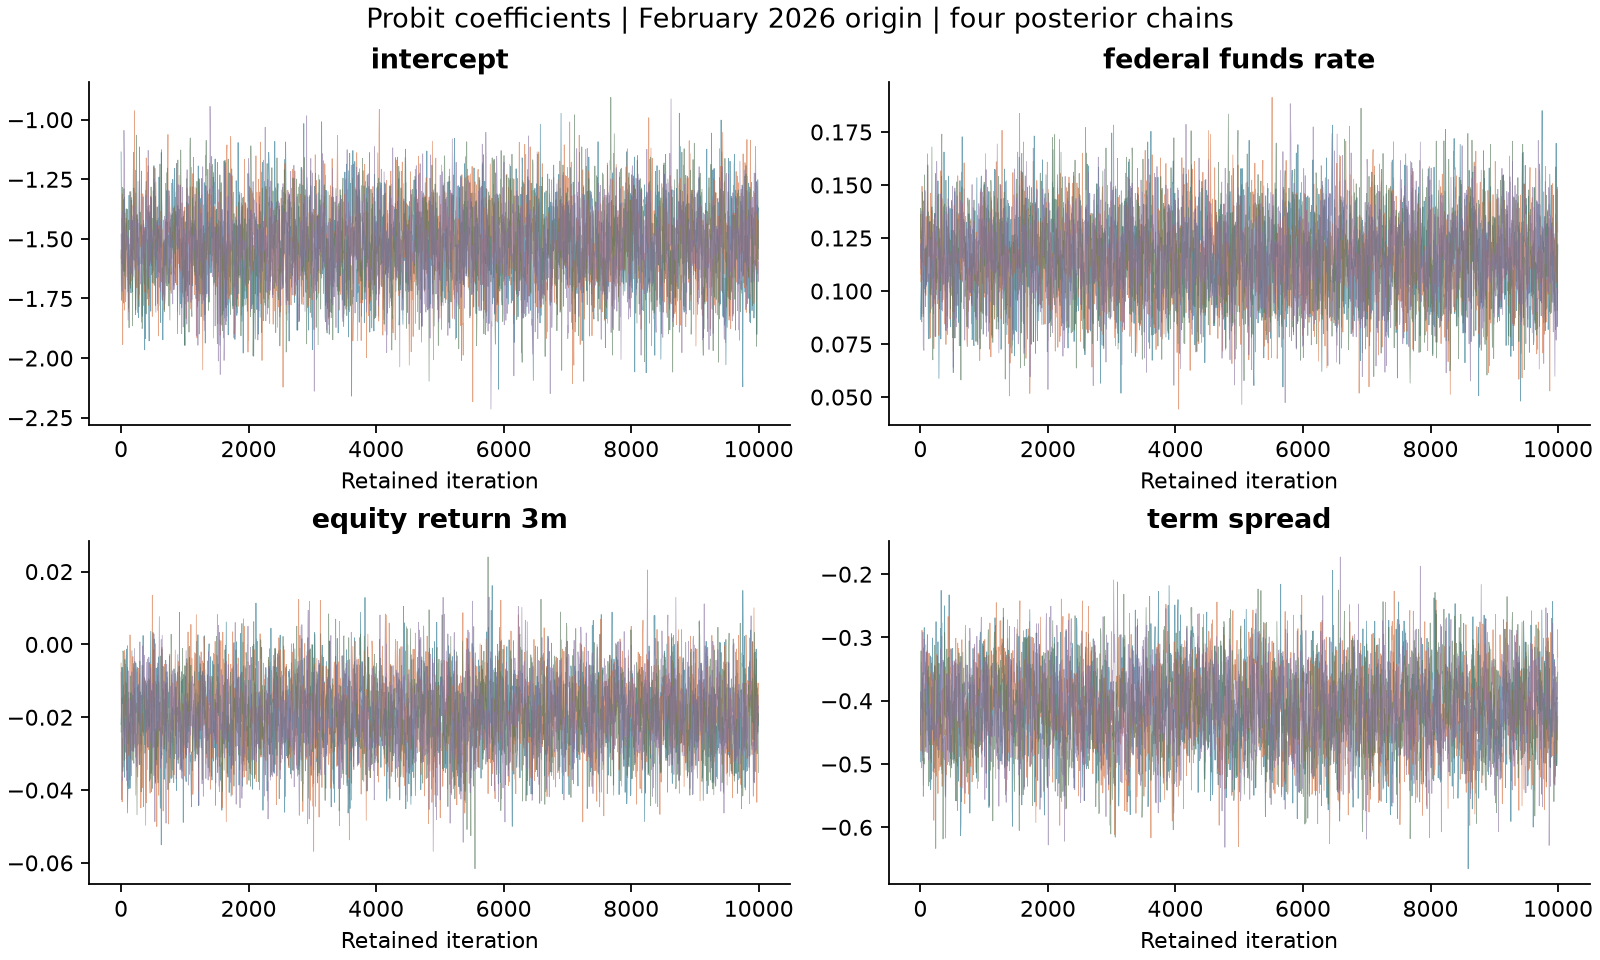

In [9]:
endpoint_coefficients = pd.read_csv(RESULTS / 'recession/probit_2026-02-28_diagnostics.csv')
display(endpoint_coefficients)
display(Image(filename=str(RESULTS / 'recession/probit_endpoint_densities.png')))
display(Image(filename=str(RESULTS / 'recession/probit_endpoint_traces.png')))

## Scores and an honest benchmark

The Beta(1,1)-smoothed historical-frequency benchmark uses the same training labels. Brier loss and negative log score reward accurate probability forecasts; smaller is better. All twelve 2008 targets are recessions in the supplied indicator, so these scores cannot establish broad calibration or discrimination. Intervals around model probabilities describe parameter uncertainty, not intervals for binary outcomes.

In [10]:
scores = json.loads((RESULTS / 'recession/recession_scores.json').read_text())
display(pd.DataFrame({k: scores[k] for k in ['probit', 'benchmark']}).T)
assert scores['all_diagnostics_passed']
endpoint = forecasts[forecasts.origin.str.startswith('2026-02')]
assert endpoint.actual.isna().all()
display(endpoint[['origin', 'target_date', 'probability', 'probability_p05', 'probability_p95']])

,n,brier,negative_log_score,log_score_clip
probit,12.00000,0.75593,2.15412,0.00000
benchmark,12.00000,0.77724,2.13379,0.00000


,origin,target_date,probability,probability_p05,probability_p95
12,2026-02-28,2027-02-28,0.08645,0.06330,0.11255


## Withholding recently dated outcomes

An 18-month label-delay sensitivity changes the available training sample. It demonstrates dependence on label availability; it does not reconstruct a historical NBER announcement calendar or turn revised predictor data into a real-time experiment.

In [11]:
delayed = pd.read_csv(RESULTS / 'recession_delay18/recession_forecasts.csv')
delayed_scores = json.loads((RESULTS / 'recession_delay18/recession_scores.json').read_text())
display(pd.DataFrame({'primary': scores['probit'], 'delay18': delayed_scores['probit']}).T)
display(delayed[['origin', 'last_training_target', 'latest_label_availability', 'training_n',
                 'probability', 'diagnostics_passed']])
assert delayed_scores['all_diagnostics_passed']

,n,brier,negative_log_score,log_score_clip
primary,12.00000,0.75593,2.15412,0.00000
delay18,12.00000,0.74243,2.08470,0.00000


,origin,last_training_target,latest_label_availability,training_n,probability,diagnostics_passed
0,2007-01-31,2005-07-31,2007-01-31,532,0.20668,True
1,2007-02-28,2005-08-31,2007-02-28,533,0.22376,True
2,2007-03-31,2005-09-30,2007-03-31,534,0.24536,True
3,2007-04-30,2005-10-31,2007-04-30,535,0.20201,True
4,2007-05-31,2005-11-30,2007-05-31,536,0.16841,True
5,2007-06-30,2005-12-31,2007-06-30,537,0.10353,True
6,2007-07-31,2006-01-31,2007-07-31,538,0.14575,True
7,2007-08-31,2006-02-28,2007-08-31,539,0.11308,True
8,2007-09-30,2006-03-31,2007-09-30,540,0.09150,True
9,2007-10-31,2006-04-30,2007-10-31,541,0.08469,True


## What this project demonstrates

Economic specification, Bayesian computation, prior sensitivity, software design by composition, input provenance, temporal validation, and communication of model limitations. The package and scientific controls are reusable. The results do not establish causality, real-time forecasting performance, or performance across all business-cycle regimes. Original input vintages and the policy model's residual structure remain material limitations.